
RESULTS WILL BE SAVED IN:
G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results

Full OR table saved.
Significant predictors table saved.
Model summary saved.


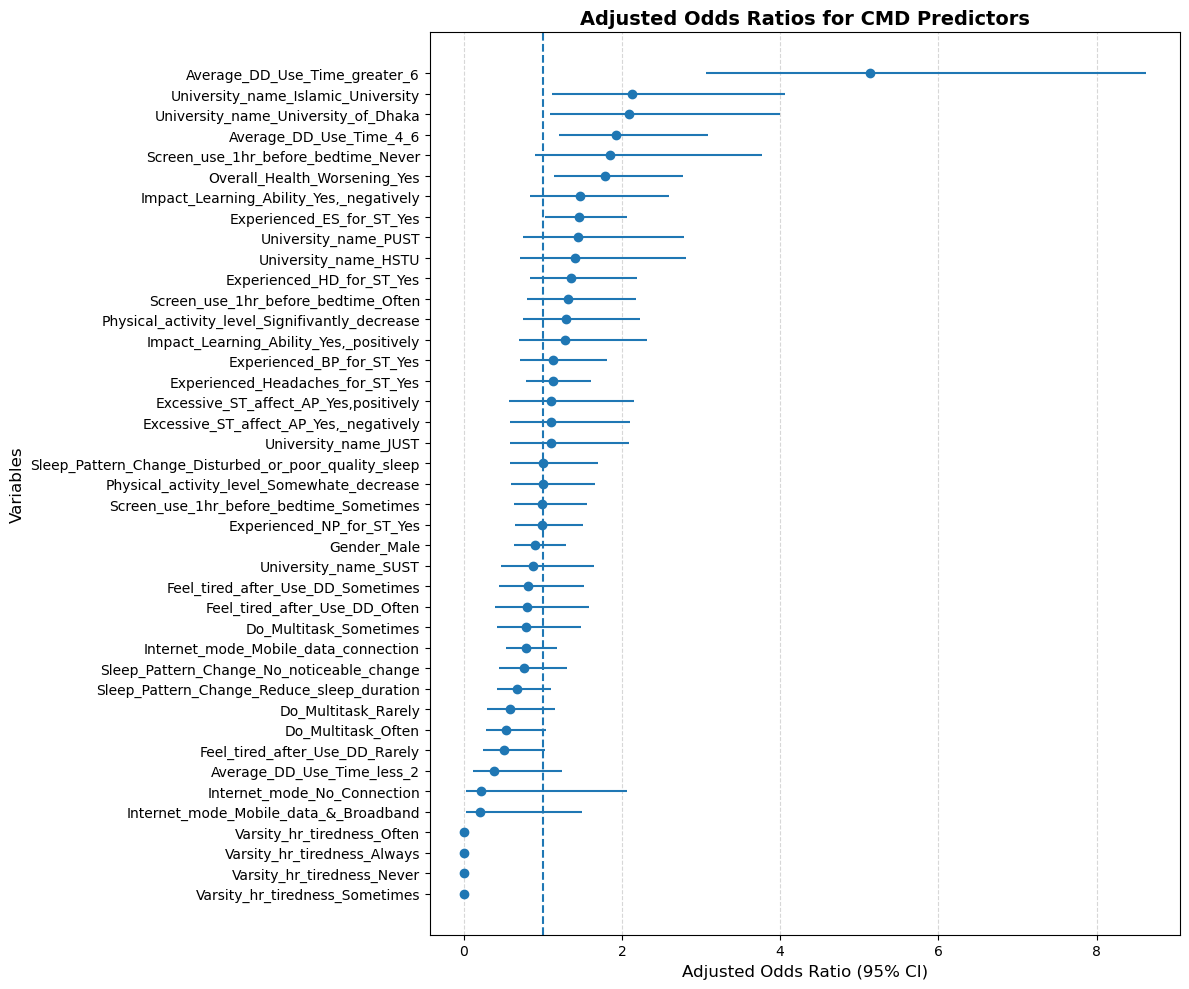

Forest plot exported successfully.
Excel results exported successfully.


EXPORTED LOGISTIC REGRESSION FILES

CSV FILES:
1. Final_CMD_Logistic_Regression_OR_Table.csv
2. Significant_CMD_Predictors.csv

TEXT FILE:
3. Logistic_Regression_Model_Summary.txt

EXCEL FILE:
4. CMD_Logistic_Regression_Results.xlsx

FIGURES:
5. CMD_Logistic_Regression_ForestPlot.png

SAVE LOCATION

G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results


In [2]:
# =========================================================
# EXPORT LOGISTIC REGRESSION RESULTS
# PUBLICATION-QUALITY OUTPUTS
# =========================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# =========================================================
# 1. DEFINE OUTPUT DIRECTORY
# =========================================================

OUTPUT_DIR = r'G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results'

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nRESULTS WILL BE SAVED IN:")

print(OUTPUT_DIR)


# =========================================================
# 2. SAVE FULL ODDS RATIO TABLE
# =========================================================

OR_table.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'Final_CMD_Logistic_Regression_OR_Table.csv'
    ),

    index=False
)

print("\nFull OR table saved.")


# =========================================================
# 3. SAVE SIGNIFICANT PREDICTORS ONLY
# =========================================================

significant_vars.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'Significant_CMD_Predictors.csv'
    ),

    index=False
)

print("Significant predictors table saved.")


# =========================================================
# 4. SAVE MODEL SUMMARY AS TEXT FILE
# =========================================================

summary_text = result.summary().as_text()

with open(

    os.path.join(

        OUTPUT_DIR,

        'Logistic_Regression_Model_Summary.txt'
    ),

    'w'
) as f:

    f.write(summary_text)

print("Model summary saved.")


# =========================================================
# 5. CREATE FOREST PLOT DATA
# =========================================================

plot_df = OR_table.copy()

# Remove intercept

plot_df = plot_df[

    plot_df['Variable'] != 'const'
]

# Sort by odds ratio

plot_df = plot_df.sort_values(

    by='Adjusted_OR'
)


# =========================================================
# 6. CREATE FOREST PLOT
# =========================================================

plt.figure(figsize=(12,10))

plt.errorbar(

    plot_df['Adjusted_OR'],
    plot_df['Variable'],

    xerr=[

        plot_df['Adjusted_OR'] - plot_df['95%_CI_Lower'],

        plot_df['95%_CI_Upper'] - plot_df['Adjusted_OR']
    ],

    fmt='o'
)


# Reference line

plt.axvline(

    x=1,
    linestyle='--'
)


# =========================================================
# 7. LABELS
# =========================================================

plt.xlabel(

    'Adjusted Odds Ratio (95% CI)',
    fontsize=12
)

plt.ylabel(

    'Variables',
    fontsize=12
)

plt.title(

    'Adjusted Odds Ratios for CMD Predictors',

    fontsize=14,
    fontweight='bold'
)


# =========================================================
# 8. GRID
# =========================================================

plt.grid(

    axis='x',
    linestyle='--',
    alpha=0.5
)


# =========================================================
# 9. SAVE FOREST PLOT
# =========================================================

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'CMD_Logistic_Regression_ForestPlot.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Forest plot exported successfully.")


# =========================================================
# 10. SAVE RESULTS INTO EXCEL
# =========================================================

excel_path = os.path.join(

    OUTPUT_DIR,

    'CMD_Logistic_Regression_Results.xlsx'
)

with pd.ExcelWriter(excel_path) as writer:

    OR_table.to_excel(

        writer,
        sheet_name='All_OR_Results',
        index=False
    )

    significant_vars.to_excel(

        writer,
        sheet_name='Significant_Predictors',
        index=False
    )

print("Excel results exported successfully.")


# =========================================================
# 11. FINAL OUTPUT SUMMARY
# =========================================================

print("""

===================================
EXPORTED LOGISTIC REGRESSION FILES
===================================

CSV FILES:
1. Final_CMD_Logistic_Regression_OR_Table.csv
2. Significant_CMD_Predictors.csv

TEXT FILE:
3. Logistic_Regression_Model_Summary.txt

EXCEL FILE:
4. CMD_Logistic_Regression_Results.xlsx

FIGURES:
5. CMD_Logistic_Regression_ForestPlot.png

===================================
SAVE LOCATION
===================================

""" + OUTPUT_DIR)